# Ejercicio 3 Cancelaciones hoteleras: comparación de clasificadores

Grupo 14.

Objetivo: predecir `is_canceled` (1 cancelada, 0 no cancelada). Se consolidan cinco métodos vistos en clase: árbol de decisión, Random Forest, XGBoost, Voting y Stacking. El F1 macro promedia el F1 de ambas clases con igual peso. Precision macro y recall macro también promedian por clase; accuracy es la proporción total de aciertos. ROC AUC evalúa el ordenamiento de probabilidades sin fijar umbral.

**Dos resultados diferentes:** el récord público de 0,89307 del Voting refinado anterior consta en el historial CSV aportado por el equipo. Esta ejecución compara nuevamente modelos y no tiene puntaje Kaggle propio. No buscamos etiquetas externas ni usamos el test de Kaggle para entrenar. Los CSV originales son los provistos por la cátedra; el paper de Antonio, de Almeida y Nunes (2019), DOI 10.1016/j.dib.2018.11.126, describe el origen, no un conjunto para completar etiquetas.

## Integrantes

- Calandria, Alén Santiago (padrón: 112103).
- Szinvelski, Sol Yohara (padrón: 112985).
- Garay Alvarado, Gustavo Alfredo (padrón: intercambio-02).
- Sosa, Matias (padrón: 113352).
- Fontanals Layos, Oriol (padrón: intercambio-03).

In [1]:
from pathlib import Path
import sys,json,hashlib,time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn,xgboost,joblib
from sklearn.base import clone
from sklearn.model_selection import train_test_split,StratifiedKFold,GridSearchCV,cross_val_predict
from sklearn.tree import DecisionTreeClassifier,plot_tree,export_text
from sklearn.ensemble import RandomForestClassifier,VotingClassifier,StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score,precision_score,recall_score,accuracy_score,roc_auc_score,confusion_matrix,ConfusionMatrixDisplay
from xgboost import XGBClassifier
ROOT=Path.cwd()
if not (ROOT/'datos/hoteles').exists() and (ROOT.parent/'datos/hoteles').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from hotels_features import make_features,make_pipeline,knn_pipeline
OUT=ROOT/'resultados/ej3';OUT.mkdir(parents=True,exist_ok=True)
train=pd.read_csv(ROOT/'datos/hoteles/hotels_train.csv');test=pd.read_csv(ROOT/'datos/hoteles/hotels_test.csv')
sample=pd.read_csv(ROOT/'datos/hoteles/sample_submission.csv')
assert train.id.is_unique and test.id.is_unique and set(train.id).isdisjoint(test.id)
assert list(sample.columns)==['id','is_canceled'] and set(sample.id)==set(test.id)
assert train.is_canceled.isin([0,1]).all() and 'is_canceled' not in test
X=train.drop(columns='is_canceled');y=train.is_canceled
Xd,Xv,yd,yv=train_test_split(X,y,test_size=.2,stratify=y,random_state=42)
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=42)
print('Train',train.shape,'Kaggle test',test.shape,'Desarrollo',len(Xd),'Validación',len(Xv))
display(y.value_counts().sort_index().to_frame('reservas'))
display(Xd.isna().sum().loc[lambda x:x>0].to_frame('faltantes_desarrollo'))
raw_columns=[c for c in X.columns if c!='id']
hd=pd.util.hash_pandas_object(Xd[raw_columns],index=False);hv=pd.util.hash_pandas_object(Xv[raw_columns],index=False)
overlap=hv.isin(set(hd));print('Fracción validación idéntica a desarrollo:',overlap.mean())
pd.DataFrame({'id':X.id,'split':np.where(X.index.isin(Xd.index),'desarrollo','validacion')}).to_csv(OUT/'particion.csv',index=False)
quality={'rows_train':len(train),'rows_kaggle':len(test),'train_shape':list(train.shape),'missing':train.isna().sum().loc[lambda s:s>0].to_dict(),
    'class_counts':{str(k):int(v) for k,v in y.value_counts().items()},'duplicate_fraction_valid':float(overlap.mean())}
def savefig(name):
    plt.tight_layout();plt.savefig(ROOT/'figuras'/f'ej3_{name}.png',dpi=140,bbox_inches='tight');plt.show()

Train (61913, 31) Kaggle test (26535, 30) Desarrollo 49530 Validación 12383
Fracción validación idéntica a desarrollo: 0.3192279738350965


,reservas
is_canceled,
0,30972
1,30941


,faltantes_desarrollo
children,2
country,180
agent,6374
company,46969


## EDA, preparación y alcance temporal

`id` se conserva para trazabilidad y se excluye de los predictores. `agent` y `company` son códigos, no magnitudes: el valor vacío representa ausencia de agencia/empresa según el paper y se codifica como categoría -1; sus indicadores señalan esa ausencia, no un dato que necesariamente debió observarse. Country y children faltantes se tratan dentro de cada fold (categoría Sin_dato y mediana, respectivamente).

Se derivan noches y huéspedes totales, fechas de llegada/reserva estimada, valor de estadía aproximado, ADR por huésped, cambio de habitación y antecedentes. Cada transformación utiliza solo esa fila; las imputaciones y el One-Hot se aprenden dentro del Pipeline de cada fold. KNN además normaliza las numéricas con MinMaxScaler. Árboles no requieren escalado.

Se conservan atípicos plausibles: no se eliminan reservas por tener muchas noches o ADR alto. ADR negativo, cero huéspedes y estadías de cero noches se cuentan como alertas; no conocemos su causa. La división por cero produce faltante imputado en train. Los duplicados entre conjuntos se informan, no se utilizan para recuperar etiquetas del test.

Esta partición estratificada 80/20 mantiene la comparación histórica, pero ya fue consultada muchas veces y tiene reservas idénticas entre desarrollo y validación. No es un test independiente de generalización. Una evaluación futura debería agrupar reservas idénticas y separar por tiempo. Las variables operativas (cambios de reserva/habitación, depósitos) pueden conocerse después de reservar: los resultados no demuestran predicción al momento de la compra.

Alertas de calidad en desarrollo: {'adr_negativo': 0, 'cero_huespedes': 56, 'cero_noches': 236}


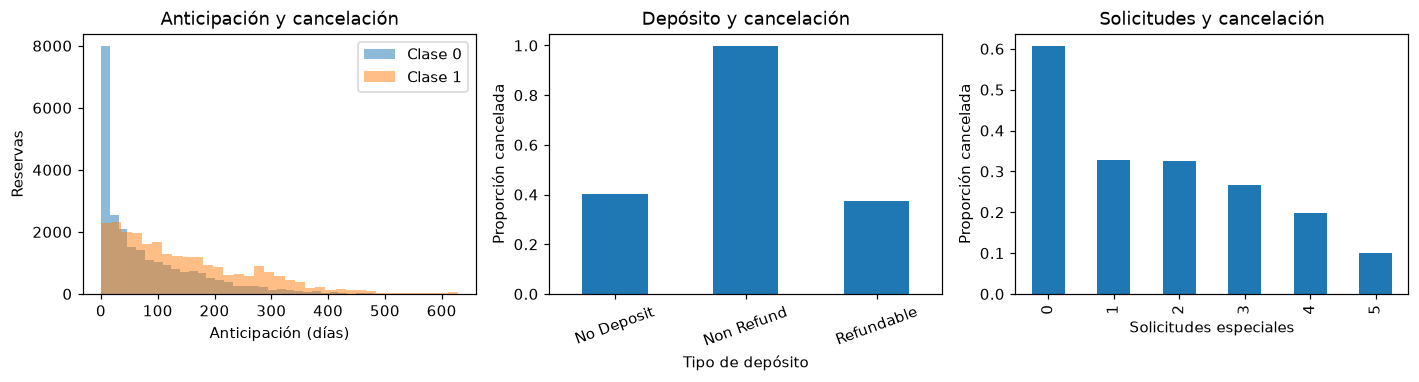

,min,50%,max
lead_time,0.0,78.0,629.0
arrival_date_year,2015.0,2016.0,2017.0
arrival_date_week_number,1.0,28.0,53.0
arrival_date_day_of_month,1.0,16.0,31.0
stays_in_weekend_nights,0.0,1.0,12.0
stays_in_week_nights,0.0,2.0,30.0
adults,0.0,2.0,40.0
children,0.0,0.0,10.0
babies,0.0,0.0,9.0
is_repeated_guest,0.0,0.0,1.0


In [2]:
alerts={'adr_negativo':int(Xd.adr.lt(0).sum()),'cero_huespedes':int((Xd.adults+Xd.children.fillna(0)+Xd.babies).eq(0).sum()),
    'cero_noches':int((Xd.stays_in_week_nights+Xd.stays_in_weekend_nights).eq(0).sum())}
print('Alertas de calidad en desarrollo:',alerts)
eda=Xd.copy();eda['is_canceled']=yd
fig,axes=plt.subplots(1,3,figsize=(13,3.6))
for label,g in eda.groupby('is_canceled'):
    axes[0].hist(g.lead_time,bins=35,alpha=.5,label=f'Clase {label}')
axes[0].set(xlabel='Anticipación (días)',ylabel='Reservas',title='Anticipación y cancelación');axes[0].legend()
eda.groupby('deposit_type').is_canceled.mean().plot.bar(ax=axes[1]);axes[1].set(xlabel='Tipo de depósito',ylabel='Proporción cancelada',title='Depósito y cancelación');axes[1].tick_params(axis='x',rotation=20)
eda.groupby('total_of_special_requests').is_canceled.mean().plot.bar(ax=axes[2]);axes[2].set(xlabel='Solicitudes especiales',ylabel='Proporción cancelada',title='Solicitudes y cancelación')
savefig('eda')
features=make_features(Xd);features.assign(is_canceled=yd).to_csv(ROOT/'datos/procesados/hoteles_desarrollo.csv.gz',index=False)
display(features.describe().T[['min','50%','max']])

## Búsqueda de hiperparámetros en desarrollo

Se ejecuta una búsqueda acotada de consolidación, con tres folds estratificados iguales para todos. Árbol: profundidad y hoja mínima; RF: profundidad y fracción de variables; XGBoost: dos combinaciones de profundidad, tasa y cantidad de árboles previamente estudiadas. El criterio es F1 macro. El mejor promedio de CV es optimista por la selección; no se presenta como evaluación anidada.

Las configuraciones provienen del trabajo semanal, pero los resultados de esta tabla se recalculan. Los modelos elegidos se ajustan a todo desarrollo y se evalúan en la misma validación histórica. El umbral se fija en 0,5 y no se reajusta mirando validación.

In [3]:
specs={
'Arbol':(DecisionTreeClassifier(random_state=42),{'model__max_depth':[12,20,None],'model__min_samples_leaf':[2,8]}),
'Random Forest':(RandomForestClassifier(n_estimators=600,min_samples_leaf=1,random_state=42,n_jobs=4),{'model__max_depth':[24,None],'model__max_features':[.25]}),
'XGBoost':(XGBClassifier(objective='binary:logistic',eval_metric='logloss',tree_method='hist',random_state=42,n_jobs=4,verbosity=0),[
    {'model__n_estimators':[900],'model__max_depth':[8],'model__learning_rate':[.08]},
    {'model__n_estimators':[1000],'model__max_depth':[10],'model__learning_rate':[.06]}])}
models={};search_results={}
for name,(model,grid) in specs.items():
    started=time.time();print('CV',name,flush=True)
    search=GridSearchCV(make_pipeline(model),grid,cv=cv,scoring='f1_macro',n_jobs=1,return_train_score=True)
    search.fit(Xd,yd);models[name]=search.best_estimator_
    pd.DataFrame(search.cv_results_).to_csv(OUT/f'cv_{name.replace(" ","_")}.csv',index=False)
    search_results[name]={'parameters':search.best_params_,'cv_f1_macro':float(search.best_score_),'seconds':time.time()-started}
    print(name,search_results[name],flush=True)
    joblib.dump(models[name],ROOT/'modelos'/f'ej3_{name.replace(" ","_")}.joblib',compress=3)

CV Arbol
Arbol {'parameters': {'model__max_depth': 20, 'model__min_samples_leaf': 2}, 'cv_f1_macro': 0.851731433993636, 'seconds': 23.57812786102295}
CV Random Forest
Random Forest {'parameters': {'model__max_depth': None, 'model__max_features': 0.25}, 'cv_f1_macro': 0.8853599218839724, 'seconds': 242.67302179336548}
CV XGBoost
XGBoost {'parameters': {'model__learning_rate': 0.06, 'model__max_depth': 10, 'model__n_estimators': 1000}, 'cv_f1_macro': 0.8831373444191, 'seconds': 91.72602939605713}


## Ensambles híbridos: Voting y Stacking

Voting soft combina las probabilidades de RF, XGBoost y KNN con pesos 2:2:1 definidos antes de esta evaluación. KNN usa 11 vecinos con peso por distancia, seleccionado en las prácticas anteriores. Stacking utiliza esos tres modelos y una regresión logística (C=1) que aprende a combinarlos con predicciones fuera de fold. Nunca se entrena el metamodelo sobre predicciones de los modelos base ajustados a las mismas filas.

Los hiperparámetros base fueron seleccionados en desarrollo; por ello la CV interna del stacking evita fuga directa de etiquetas, pero no constituye una evaluación anidada de toda la búsqueda. La comparación final se hace en la validación externa histórica ya advertida.

In [4]:
bases=[('rf',clone(models['Random Forest'])),('xgb',clone(models['XGBoost'])),('knn',knn_pipeline(scale='minmax',k=11))]
print('Ajustando Voting',flush=True)
models['Voting']=VotingClassifier(estimators=bases,voting='soft',weights=[2,2,1],n_jobs=1).fit(Xd,yd)
joblib.dump(models['Voting'],ROOT/'modelos/ej3_Voting.joblib',compress=3)
print('Ajustando Stacking con predicciones fuera de fold',flush=True)
models['Stacking']=StackingClassifier(estimators=bases,final_estimator=LogisticRegression(C=1,max_iter=2000,random_state=42),
    cv=cv,stack_method='predict_proba',passthrough=False,n_jobs=1).fit(Xd,yd)
joblib.dump(models['Stacking'],ROOT/'modelos/ej3_Stacking.joblib',compress=3)
print('Coeficientes metamodelo [RF, XGB, KNN]:',models['Stacking'].final_estimator_.coef_)

Ajustando Voting
Ajustando Stacking con predicciones fuera de fold
Coeficientes metamodelo [RF, XGB, KNN]: [[5.03850131 1.16926181 1.04440412]]


## Evaluación común y matrices de confusión

Filas de la matriz: clase real; columnas: predicha. Falso positivo: una reserva que no canceló se predice cancelada. Falso negativo: se pierde una cancelación. No tienen necesariamente el mismo costo económico, aunque la competencia utiliza F1 macro. La brecha entre entrenamiento y validación muestra sobreajuste; los resultados de entrenamiento no miden generalización.

{'modelo': 'Arbol', 'conjunto': 'train', 'f1_macro': 0.9236451005127732, 'precision_macro': 0.9255013818430072, 'recall_macro': 0.9237386898478996, 'accuracy': 0.923722996163941, 'roc_auc': 0.9806829718731778}
{'modelo': 'Arbol', 'conjunto': 'validacion', 'f1_macro': 0.8508497810684357, 'precision_macro': 0.8525210325092882, 'recall_macro': 0.851023942823544, 'accuracy': 0.8510054106436243, 'roc_auc': 0.9016409171230422}
{'modelo': 'Random Forest', 'conjunto': 'train', 'f1_macro': 0.9964869775893398, 'precision_macro': 0.9964872115579293, 'recall_macro': 0.9964872115579293, 'accuracy': 0.9964869775893398, 'roc_auc': 0.9997668012145492}
{'modelo': 'Random Forest', 'conjunto': 'validacion', 'f1_macro': 0.8890395456025981, 'precision_macro': 0.8890621582526914, 'recall_macro': 0.8890393836804604, 'accuracy': 0.8890414277638699, 'roc_auc': 0.9615904640865474}
{'modelo': 'XGBoost', 'conjunto': 'train', 'f1_macro': 0.9817681862361556, 'precision_macro': 0.9818222044151704, 'recall_macro': 0.

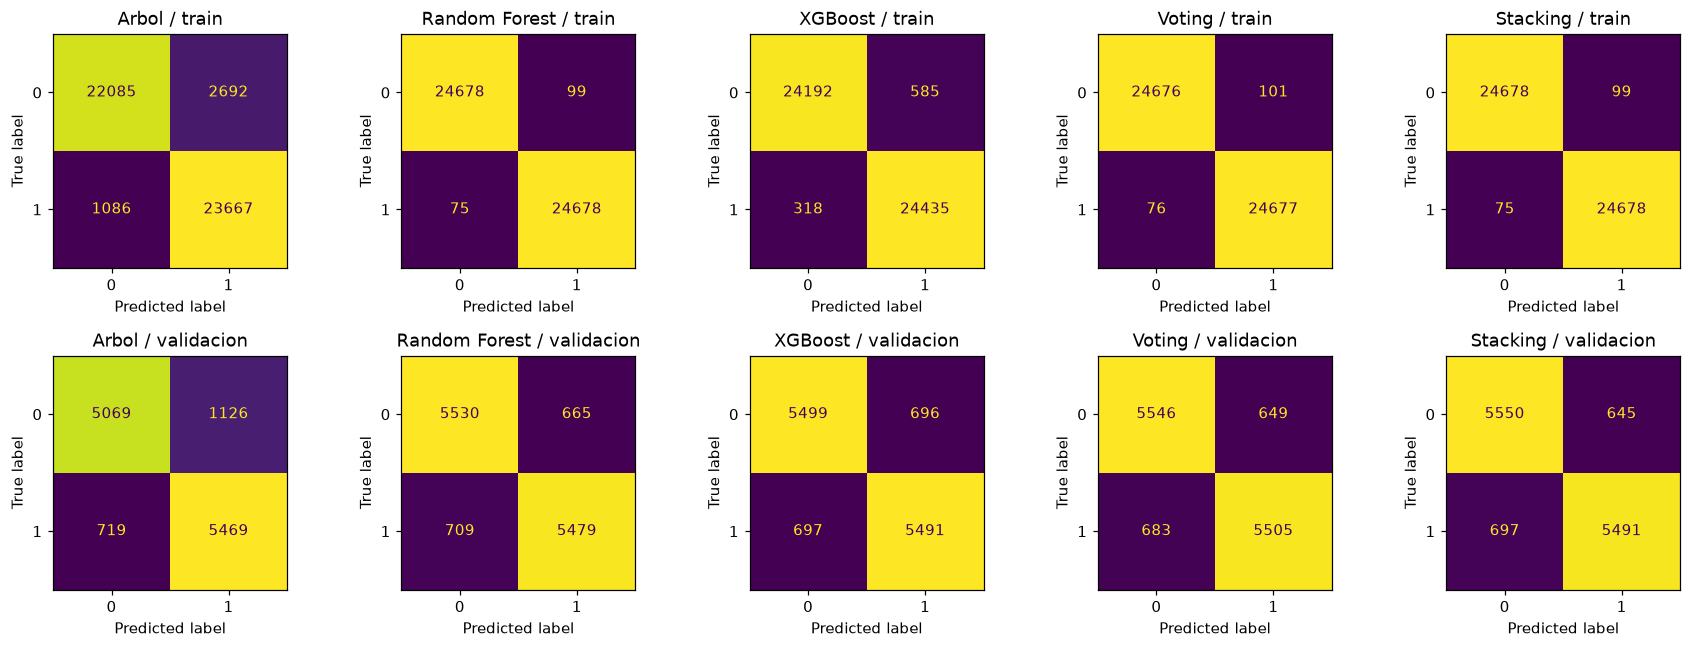

,modelo,conjunto,f1_macro,precision_macro,recall_macro,accuracy,roc_auc
0,Arbol,train,0.923645,0.925501,0.923739,0.923723,0.980683
1,Arbol,validacion,0.850850,0.852521,0.851024,0.851005,0.901641
2,Random Forest,train,0.996487,0.996487,0.996487,0.996487,0.999767
3,Random Forest,validacion,0.889040,0.889062,0.889039,0.889041,0.961590
4,XGBoost,train,0.981768,0.981822,0.981771,0.981769,0.998651
5,XGBoost,validacion,0.887507,0.887507,0.887507,0.887507,0.959638
6,Voting,train,0.996426,0.996427,0.996427,0.996426,0.999814
7,Voting,validacion,0.892432,0.892446,0.892432,0.892433,0.962252
8,Stacking,train,0.996487,0.996487,0.996487,0.996487,0.999821
9,Stacking,validacion,0.891623,0.891655,0.891623,0.891626,0.962492


In [5]:
metrics=[];predictions=pd.DataFrame({'id':Xv.id,'real':yv});matrices={};overlap_metrics=[]
fig,axes=plt.subplots(2,5,figsize=(16,6))
for j,(name,model) in enumerate(models.items()):
    for i,(split,x,ytrue) in enumerate([('train',Xd,yd),('validacion',Xv,yv)]):
        prob=model.predict_proba(x)[:,1];pred=(prob>=.5).astype(int)
        row={'modelo':name,'conjunto':split,'f1_macro':float(f1_score(ytrue,pred,average='macro')),
            'precision_macro':float(precision_score(ytrue,pred,average='macro',zero_division=0)),
            'recall_macro':float(recall_score(ytrue,pred,average='macro',zero_division=0)),
            'accuracy':float(accuracy_score(ytrue,pred)),'roc_auc':float(roc_auc_score(ytrue,prob))}
        metrics.append(row);print(row,flush=True)
        cm=confusion_matrix(ytrue,pred,labels=[0,1]);matrices[name+'_'+split]=cm.tolist()
        ConfusionMatrixDisplay(cm,display_labels=['0','1']).plot(ax=axes[i,j],colorbar=False,values_format='d');axes[i,j].set_title(name+' / '+split)
        if split=='validacion':
            predictions[name]=prob
            for group,mask in [('sin coincidencia',~overlap),('con coincidencia',overlap)]:
                overlap_metrics.append({'modelo':name,'grupo':group,'filas':int(mask.sum()),'f1_macro':float(f1_score(ytrue.loc[mask],pred[mask],average='macro'))})
savefig('matrices')
table=pd.DataFrame(metrics);table.to_csv(OUT/'metricas.csv',index=False);display(table)
predictions.to_csv(OUT/'probabilidades_validacion.csv',index=False)
pd.DataFrame(overlap_metrics).to_csv(OUT/'metricas_solapamiento.csv',index=False)

## Interpretabilidad: reglas, árboles e importancias

Se dibujan los primeros niveles del árbol completo y de un árbol de RF; no representan todas las reglas ni al bosque completo. Las importancias por reducción de impureza (árbol/RF) pueden favorecer variables con muchos cortes; las de XGBoost son gain normalizado y no tienen la misma escala conceptual. No son efectos causales ni un ranking universal. Un split en una dummy de depósito separa presencia/ausencia de esa categoría, no una magnitud del depósito.

Para XGBoost se representa el primer árbol y sus tres primeros niveles a partir del dump JSON, sin requerir Graphviz. Sus hojas suman ajustes al logit; no son probabilidades individuales y el primer árbol no resume el modelo de boosting.

Arbol primeras reglas |--- cat__deposit_type_Non Refund <= 0.50
|   |--- num__room_changed <= 0.50
|   |   |--- num__lead_time <= 11.50
|   |   |   |--- truncated branch of depth 18
|   |   |--- num__lead_time >  11.50
|   |   |   |--- truncated branch of depth 18
|   |--- num__room_changed >  0.50
|   |   |--- cat__country_PRT <= 0.50
|   |   |   |--- truncated branch of depth 16
|   |   |--- cat__country_PRT >  0.50
|   |   |   |--- truncated branch of depth 18
|--- cat__deposit_type_Non Refund >  0.50
|   |--- cat__country_DEU <= 0.50
|   |   |--- cat__company_174 <= 0.50
|   |   |   |--- truncated branch of depth 12
|   |   |--- cat__company_174 >  0.50
|   |   |   |--- class: 0
|   |--- cat__country_DEU >  0.50
|   |   |--- class: 0

Random Forest primeras reglas |--- cat__deposit_type_Non Refund <= 0.50
|   |--- cat__market_segment_Online TA <= 0.50
|   |   |--- num__total_previous_bookings <= 0.50
|   |   |   |--- truncated branch of depth 35
|   |   |--- num__total_previous_boo

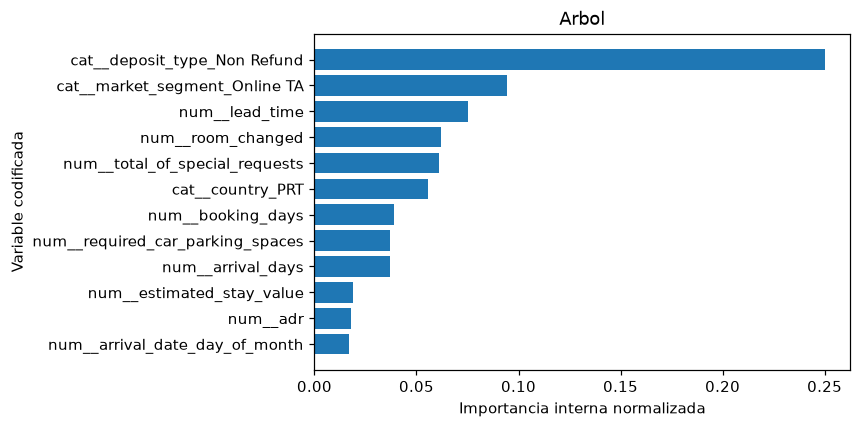

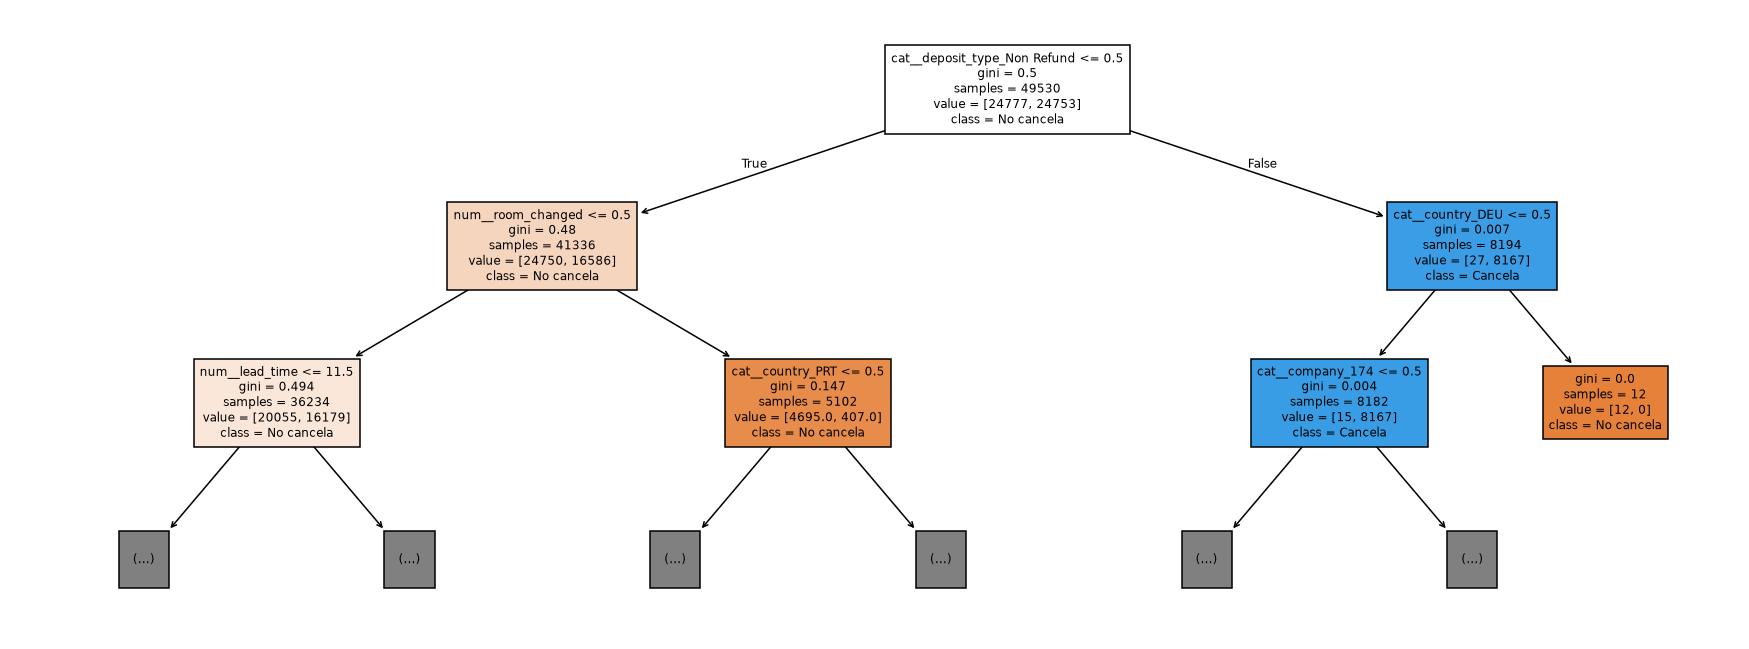

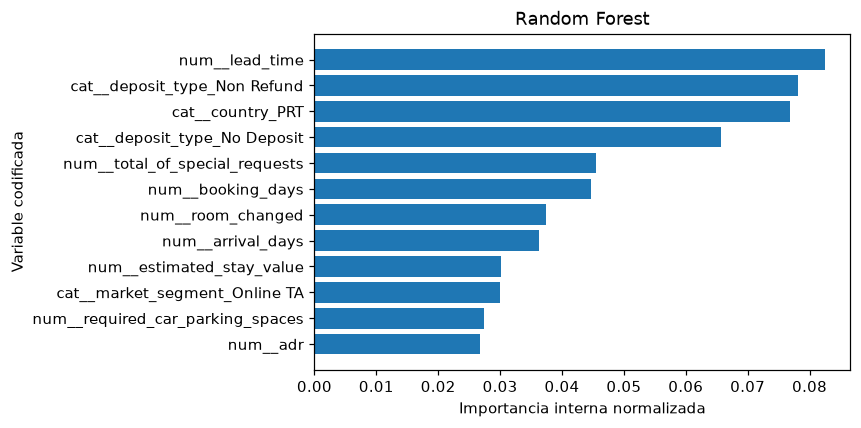

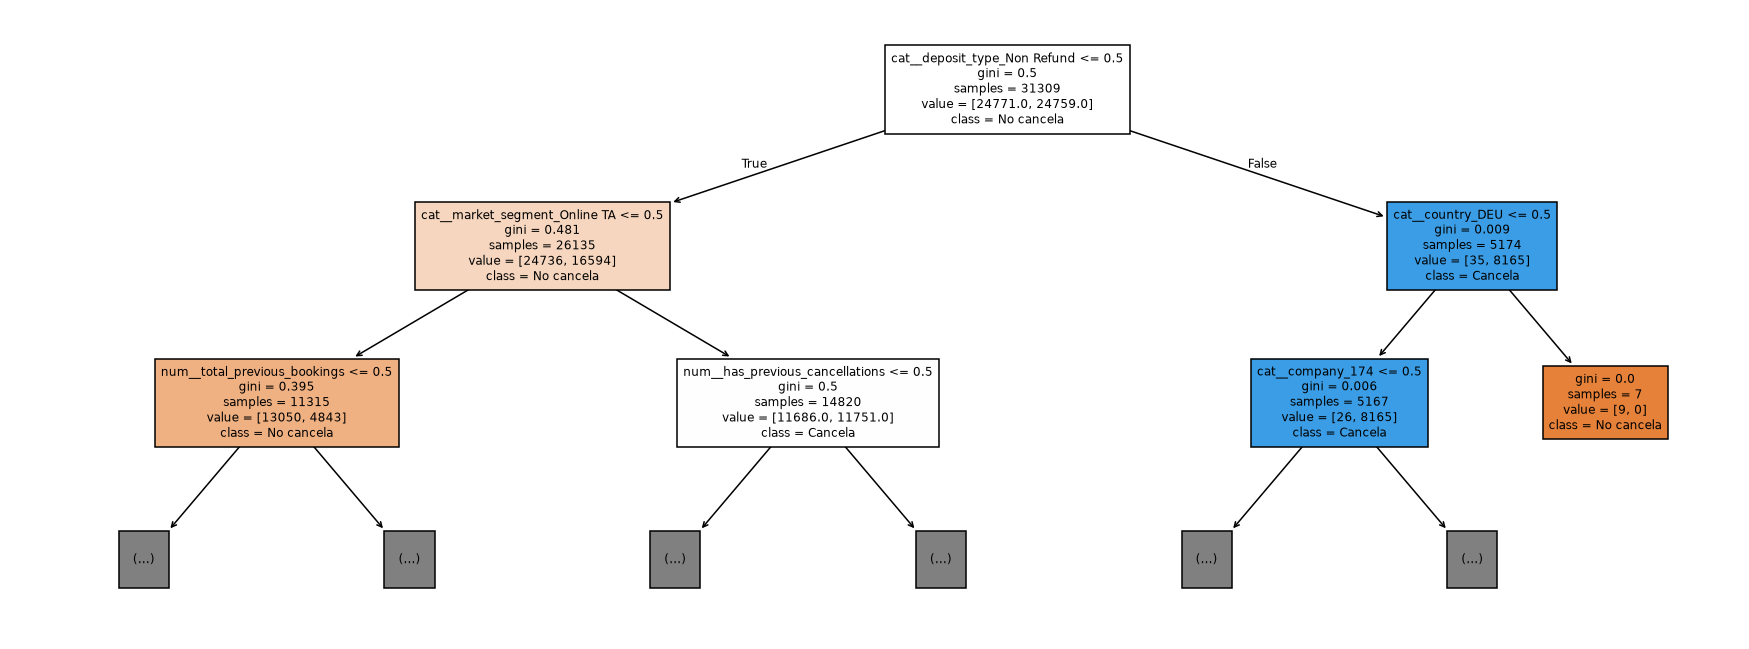

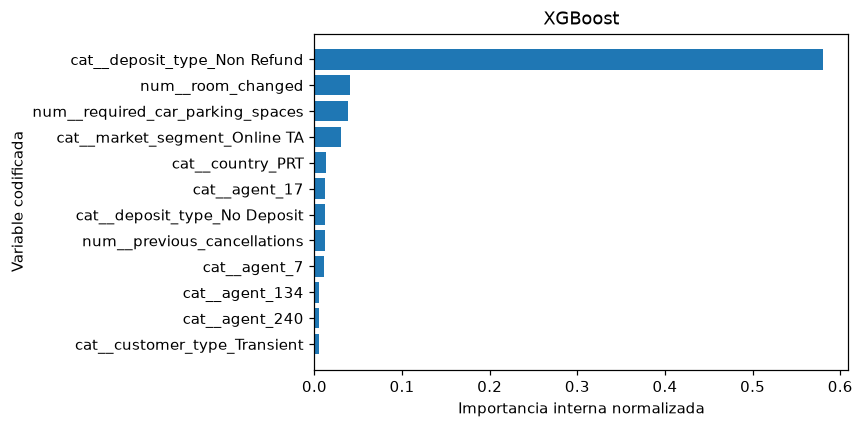

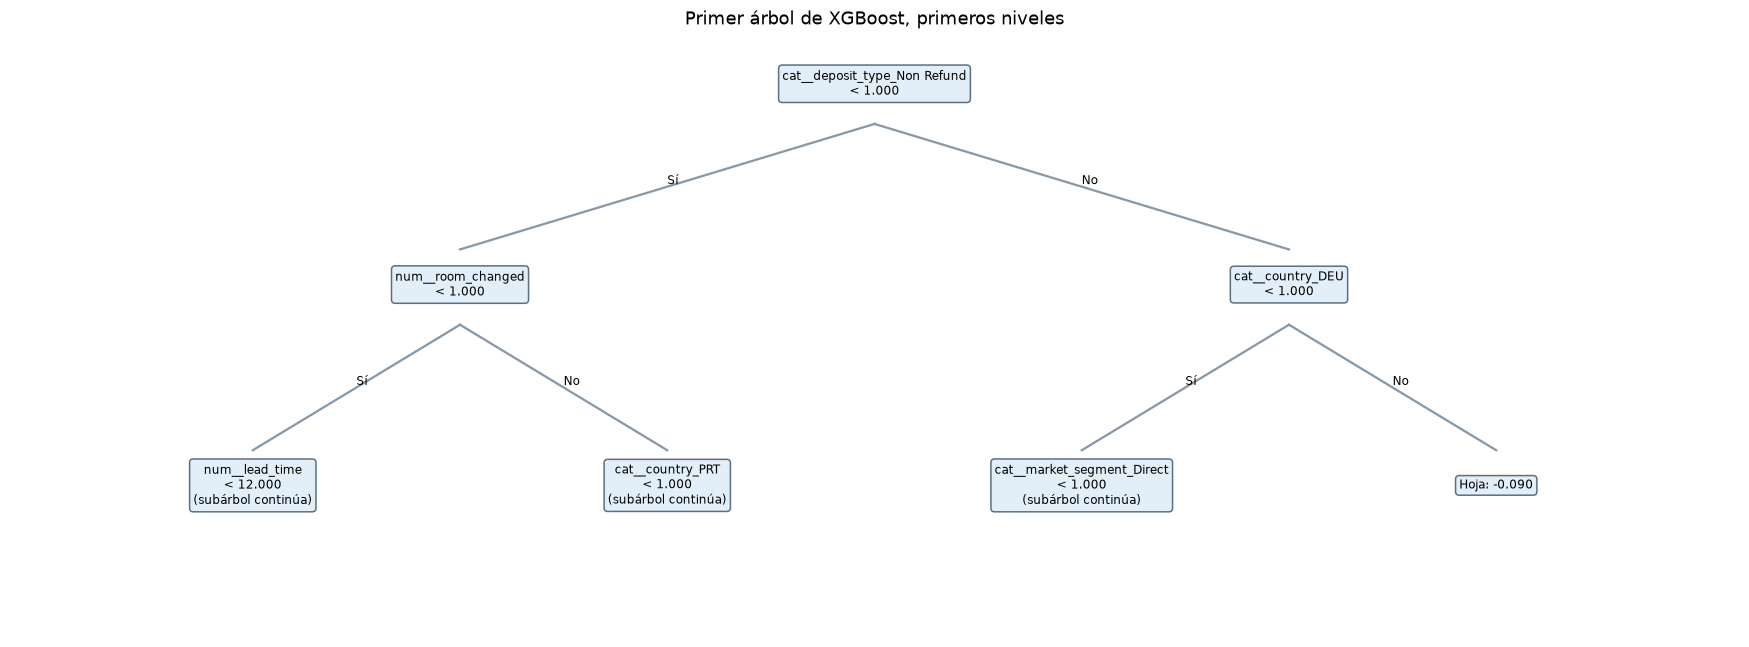

In [6]:
importances={};rules={}
for name in ['Arbol','Random Forest','XGBoost']:
    pipe=models[name];names=pipe.named_steps['preprocess'].get_feature_names_out();est=pipe.named_steps['model']
    imp=pd.DataFrame({'variable':names,'importancia':est.feature_importances_}).sort_values('importancia',ascending=False)
    imp.to_csv(OUT/f'importancias_{name.replace(" ","_")}.csv',index=False);importances[name]=imp.head(10).to_dict('records')
    fig,ax=plt.subplots(figsize=(8,4));top=imp.head(12).iloc[::-1];ax.barh(top.variable,top.importancia);ax.set(xlabel='Importancia interna normalizada',title=name,ylabel='Variable codificada');savefig('importancia_'+name.replace(' ','_'))
    if name!='XGBoost':
        tree=est if name=='Arbol' else est.estimators_[0]
        rules[name]=export_text(tree,feature_names=list(names),max_depth=2)
        print(name,'primeras reglas',rules[name])
        fig,ax=plt.subplots(figsize=(16,6));plot_tree(tree,max_depth=2,feature_names=list(names),class_names=['No cancela','Cancela'],filled=True,fontsize=8,ax=ax);savefig('arbol_'+name.replace(' ','_'))
    else:
        root=json.loads(est.get_booster().get_dump(dump_format='json',with_stats=True)[0]);rules[name]=root
        fig,ax=plt.subplots(figsize=(16,6));ax.set(xlim=(0,1),ylim=(-.1,1.1));ax.axis('off')
        def draw(node,x=.5,y=1.,width=.48,depth=0):
            if 'leaf' in node:label=f"Hoja: {node['leaf']:.3f}"
            else:
                key=node['split'];feature=names[int(key[1:])] if key.startswith('f') and key[1:].isdigit() else key
                label=f"{feature}\n< {node['split_condition']:.3f}"
                if depth>=2:label+='\n(subárbol continúa)'
            ax.text(x,y,label,ha='center',va='center',fontsize=8,bbox=dict(boxstyle='round',facecolor='#e2eef8',edgecolor='#5b7182'))
            if depth<2:
                children=node.get('children',[])
                for i,ch in enumerate(children):
                    xx=x+(-width/2 if i==0 else width/2);yy=y-.4
                    ax.plot([x,xx],[y-.08,yy+.07],color='#8899aa',zorder=0)
                    ax.text((x+xx)/2,(y+yy)/2,'Sí' if ch['nodeid']==node['yes'] else 'No',fontsize=8)
                    draw(ch,xx,yy,width/2,depth+1)
        draw(root);ax.set_title('Primer árbol de XGBoost, primeros niveles');savefig('arbol_XGBoost')
winner=table.loc[table.conjunto.eq('validacion')].sort_values('f1_macro',ascending=False).iloc[0].modelo
result={'quality':quality,'alerts_development':alerts,'cv':search_results,'metrics':metrics,'confusion_matrices':matrices,
    'importances':importances,'winner_validation':winner,'overlap_metrics':overlap_metrics,'threshold':.5,
    'meta_coefficients':models['Stacking'].final_estimator_.coef_.tolist(),'kaggle_score_this_run':None,
    'versions':{'sklearn':sklearn.__version__,'xgboost':xgboost.__version__,'numpy':np.__version__,'pandas':pd.__version__}}
(OUT/'resultados.json').write_text(json.dumps(result,indent=2,ensure_ascii=False),encoding='utf-8')
(OUT/'reglas.json').write_text(json.dumps(rules,indent=2,ensure_ascii=False),encoding='utf-8')

## Conclusiones y experimentos anteriores

La tabla anterior permite elegir según F1 macro de validación, considerando también complejidad y sobreajuste. No prueba superioridad en un test nuevo ni en el ranking privado. El reporte separa esta comparación de los puntajes públicos históricos.

La ingeniería de fechas, composición de la reserva, antecedentes y mezcla de modelos mostró utilidad en las iteraciones semanales; la ablación añadida al final mide el conjunto de variables derivadas para el árbol, no el aporte individual de cada transformación ni su efecto en todos los modelos. No se afirma que todo preprocesamiento mejore por sí solo. Los árboles no necesitan normalización; KNN sí es sensible a escalas.

Ensayos posteriores no garantizaron progreso: una red neuronal obtuvo F1 macro CV 0,86210 y con PCA 0,85739 en los registros históricos; el Voting controlado posterior no superó al control en su búsqueda. Estas cifras pertenecen a experimentos anteriores, no a modelos recalculados aquí. Sus resúmenes se adjuntan con procedencia para no perder los intentos fallidos.

Con más tiempo: validación agrupada/temporal, ablación de features con los mismos folds, intervalos de incertidumbre y evaluación de costos de falsos positivos/negativos. Evitar seguir seleccionando por diferencias minúsculas del leaderboard, que pueden no repetirse en el privado.

Los modelos guardados están ajustados sobre desarrollo, para reproducir esta evaluación. Antes de producir una nueva submission deben reentrenarse sobre todo train; este notebook no reemplaza automáticamente el CSV campeón ni lo sube a Kaggle.

## Experimento controlado de preprocesamiento: ablación del árbol

Para no atribuir mejoras a intuición, comparamos las variables originales contra las originales más las derivadas del notebook. Se mantienen los mismos folds, semilla, imputación/encoding y parámetros del árbol elegido. Se excluye id en ambos y se tratan agent/company como códigos. Esta es una ablación exploratoria de un único algoritmo: sus hiperparámetros fueron seleccionados usando ingeniería, por lo que no estima la superioridad de cada representación con ajuste independiente ni permite extrapolar la diferencia a RF/Voting.

In [7]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold,train_test_split,cross_val_score
from sklearn.preprocessing import FunctionTransformer
from sklearn.tree import DecisionTreeClassifier
ROOT=Path.cwd()
if not (ROOT/'datos/hoteles').exists() and (ROOT.parent/'datos/hoteles').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from hotels_features import make_pipeline
raw=pd.read_csv(ROOT/'datos/hoteles/hotels_train.csv')
X=raw.drop(columns='is_canceled');y=raw.is_canceled
Xd,Xv,yd,yv=train_test_split(X,y,test_size=.2,stratify=y,random_state=42)
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=42)
params=json.loads((ROOT/'resultados/ej3/resultados.json').read_text())['cv']['Arbol']['parameters']
def basic_features(frame):
    z=frame.drop(columns='id').copy()
    for col in ['agent','company']:z[col]=z[col].fillna(-1).astype(int).astype(str)
    return z
engineered=make_pipeline(DecisionTreeClassifier(random_state=42))
engineered.set_params(**params)
basic=clone(engineered);basic.set_params(features=FunctionTransformer(basic_features,validate=False))
rows=[]
for label,model in [('Originales',basic),('Con ingenieria',engineered)]:
    scores=cross_val_score(model,Xd,yd,cv=cv,scoring='f1_macro',n_jobs=1)
    rows.append({'representacion':label,'media_f1_macro':float(scores.mean()),'std':float(scores.std()),'folds':scores.tolist()})
    print(label,scores,float(scores.mean()),flush=True)
delta=rows[1]['media_f1_macro']-rows[0]['media_f1_macro']
print('Diferencia de F1 macro CV, ingeniería menos originales:',delta)
pd.DataFrame(rows).to_csv(ROOT/'resultados/ej3/ablacion_arbol.csv',index=False)
(ROOT/'resultados/ej3/ablacion_arbol.json').write_text(json.dumps({'results':rows,'delta':delta,'scope':'Arbol con parametros fijos y mismos folds; sin consultar holdout'},indent=2),encoding='utf-8')

Originales [0.84578644 0.8435459  0.84851124] 0.845947861747327
Con ingenieria [0.85205066 0.84938127 0.85376237] 0.851731433993636
Diferencia de F1 macro CV, ingeniería menos originales: 0.005783572246309099


La diferencia observada fue 0.00578 puntos de F1 macro CV. Es evidencia limitada al árbol y estos parámetros, no una ganancia garantizada en Kaggle. Como siguiente paso se repetiría una ablación con búsqueda independiente para cada representación.

## Interpretación concreta de las raíces

**Arbol**: La primera regla compara cat__deposit_type_Non Refund con 0.500: a la izquierda quedan valores menores o iguales, y a la derecha los mayores. Es una variable One-Hot: un umbral entre 0 y 1 separa ausencia y presencia de esa categoría, no el importe del depósito ni una cantidad.

**Random Forest**: La primera regla compara cat__deposit_type_Non Refund con 0.500: a la izquierda quedan valores menores o iguales, y a la derecha los mayores. Es una variable One-Hot: un umbral entre 0 y 1 separa ausencia y presencia de esa categoría, no el importe del depósito ni una cantidad. En este árbol, samples cuenta filas distintas del bootstrap y value incorpora sus repeticiones; por eso las cantidades pueden no sumar lo mismo.

**XGBoost**: La raíz evalúa cat__deposit_type_Non Refund < 1.000. La rama Sí tiene nodeid 1; la rama No, 2. La imputación del pipeline resuelve faltantes antes del árbol. Estas reglas se aplican a variables codificadas, no a etiquetas verdaderas.

## Principales submissions históricas

Fuente: `resultados/historicos/envios_competencia.csv`, 63 registros; 62 completos con puntaje y 1 error sin score. Se conserva el archivo original sin cambios.

Se muestra el mejor envío público identificado por método, no el último ni el promedio. La red neuronal se incluye como experimento adicional. La comparación de los cinco modelos entrenados con la misma partición permanece separada.

| Método | Registro | F1 local histórico | Público Kaggle | Privado Kaggle |
|---|---:|---:|---:|---|
| Árbol | #57 | N/D | 0,86244 | No disponible |
| Random Forest | #52 | 0,88815 | 0,88812 | No disponible |
| XGBoost | #31 | N/D | 0,88742 | No disponible |
| Voting | #7 | 0,89243 | 0,89307 | No disponible |
| Stacking | #20 | 0,89211 | 0,89129 | No disponible |
| Red neuronal | #1 | 0,86642 | 0,86820 | No disponible |

“F1 local histórico” es el Test Score de una validación con etiquetas, no del test Kaggle sin etiquetas. No se sustituyen faltantes con métricas de la nueva consolidación.

## Identificación exacta

- **#57 Árbol**: `submission_arbol_variante_b.csv`; SOL YOHARA MILENA SZINVELSKI.
  Descripción original: Árbol podado con variables derivadas simples.
  Registro local: Existe una variante B local con nombre distinto; no se confirmó identidad con el upload. Se deja N/D.
- **#52 Random Forest**: `submission_semana_2_random_forest.csv`; ALÉN SANTIAGO CALANDRIA.
  Descripción original: primer random forest
  Registro local: Nombre, autor y experimento histórico coincidentes; umbral 0,49.
- **#31 XGBoost**: `submission_flujo2_xgb_ordinal.csv`; Matias Sosa.
  Descripción original: n_estimators=1600, learning_rate=0.025, max_depth=0, max_leaves=128, grow_policy='lossguide', min_child_weight=1, subsample=0.90, colsample_bytree=0.95, gamma=0.01, reg_alpha=0.05, reg_lambda=0.4, random_state=42, n_jobs=-1, eval_metric='logloss'
  Registro local: Registro de Matias Sosa; no se aportó evaluación local de esta configuración. El mismo nombre aparece en #37 con otros parámetros y score.
- **#7 Voting**: `submission_voting_refinado.csv`; ALÉN SANTIAGO CALANDRIA.
  Descripción original: Voting RF + XGB profundo + KNN
  Registro local: Nombre, autor y configuración coincidentes.
- **#20 Stacking**: `submission_semana_4_stacking_sz.csv`; SOL YOHARA MILENA SZINVELSKI.
  Descripción original: Stacking RF + XGBoost + KNN — umbral 0.46
  Registro local: Alias _sz del Stacking histórico: resultado confirmado previamente por el usuario y descripción coincidente; umbral 0,46.
- **#1 Red neuronal**: `submission_red_neuronal.csv`; ALÉN SANTIAGO CALANDRIA.
  Descripción original: red Keras 128-64, Dropout, sin PCA, CV3.
  Registro local: Nombre, autor y arquitectura 128-64 sin PCA coincidentes.

## Límites y casos ambiguos

- Los nombres random_tree no distinguen árbol individual de bosque. Si fueran árboles, cambiaría el máximo de esa familia; no se asignan por intuición.
- La clasificación de familia se infiere del nombre y descripción del historial, no de inspección del código de todos los integrantes.
- Los scores locales son registros históricos, no los de la nueva comparación común. N/D no significa cero.
- El historial no incluye hashes de los uploads. Las correspondencias locales no son una verificación byte a byte.
- Antigüedad es texto relativo: no se convierte en fechas exactas sin fecha de captura conocida.
- La selección por leaderboard público no garantiza el mejor resultado privado.

| Registro | Archivo | Score | Motivo |
|---:|---|---:|---|
| #43 | `submission_flujo1_grid_opt.csv` | 0,85334 | Nombre sin algoritmo inequívoco y sin descripción |
| #49 | `submission_random_tree_encoded.csv` | 0,87008 | Nombre sin algoritmo inequívoco y sin descripción |
| #50 | `submission_random_tree_variables.csv` | 0,87288 | Nombre sin algoritmo inequívoco y sin descripción |

El intento #44 figura como Error y no participa del máximo. Los otros ensambles #8 y #9 se preservan en el detalle sin atribuirles una técnica no confirmada.

El mejor registro general es el Voting refinado #7 (0,89307). El segundo registro general es Voting diversidad #2 (0,89243); no es el mejor de otra familia. No se borran envíos ni se cambian selecciones en Kaggle.

Los JSON históricos originales conservan sus valores iniciales de kaggle_score. Este documento y seleccion_submissions.json agregan la evidencia posterior sin reescribir los experimentos antiguos.
